# 05 - Accuracy as a function of semantic distance

Now that we have the composites and their predictions, we can finally look at the main question of the paper: how does recognition change as the object and the background become semantically less related?

Every composite places an object on a background at a known position along the semantic axis from notebook 01. The code below takes the prediction CSVs from notebook 03, matches them with the composite metadata, and plots the accuracy as a function of this semantic distance. Afterwards, we check that the decline is not an artefact of how we plot it, look at how individual backgrounds behave, and test whether the result depends on the semantic axis we use.

In [1]:
from pathlib import Path

# Repository paths
REPO_ROOT = Path.cwd()
DATA_DIR = REPO_ROOT / "data"
OUTPUT_DIR = REPO_ROOT / "outputs"
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CLASS_INDEX = REPO_ROOT / "helper_files" / "imagenet_class_index.json"

# Prediction CSVs from notebook 03 and the composite metadata from notebook 02
PREDICTIONS_DIR = OUTPUT_DIR / "predictions"
COMPOSITES_DIR = REPO_ROOT / "ImageNet-OOC1k" / "generated" / "composites"

# Semantic axes from notebook 01: the consensus and the alternative axes for the last section
SEMANTIC_AXES_DIR = DATA_DIR / "semantic_axes"

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Analysis and plotting functions live outside the notebook to keep it readable.
from ooc1k.analysis.semantic_distance import (
    fit_logistic_regressions,
    get_accuracy_curves,
    get_accuracy_drop,
    get_background_trends,
    get_model_curves,
    get_original_accuracy,
    get_trend_group_curves,
    get_wordnet_curves,
    load_class_hash_index,
    load_composite_predictions,
    rerank_composites,
)
from ooc1k.plotting.d_semantic_distance import (
    plot_accuracy_vs_distance,
    plot_accuracy_vs_distance_all_models,
    plot_alternative_axes,
    plot_background_trends,
)

## Settings

`MAIN_MODELS` are the six models of the main figures. `ALL_MODELS` are all models with composite predictions in `PREDICTIONS_DIR`, so all 35 if you ran notebook 03 with `ALL_MODELS`. `SUPERVISED_MODELS` are the main models without CLIP, which we use for the background analysis and the alternative axes.

`BIN_WIDTH` sets how many ranks we group into one point of the curves.

In [3]:
MAIN_MODELS = ["ViT-B-16", "ViT-L-16", "DeiT-B-16", "ResNet-50", "EfficientNet-B3", "CLIP-ViT-B-16"]
ALL_MODELS = sorted({path.name.split("_composite_ooc_")[0] for path in PREDICTIONS_DIR.glob("*_composite_ooc_*.csv")})
SUPERVISED_MODELS = [model for model in MAIN_MODELS if model != "CLIP-ViT-B-16"]

# Classifier head of each supervised main model, saved by notebook 01
HEAD_MATRICES = {
    "ViT-B-16": "vit_base_patch16_224",
    "ViT-L-16": "vit_large_patch16_224",
    "DeiT-B-16": "deit_base_patch16_224",
    "ResNet-50": "resnet50",
    "EfficientNet-B3": "efficientnet_b3",
}

BIN_WIDTH = 25              # ranks per bin in the accuracy curves
TREND_BIN_WIDTH = 50        # ranks per bin when we look at single backgrounds

print(f"{len(ALL_MODELS)} models with composite predictions in {PREDICTIONS_DIR}")

35 models with composite predictions in /pfss/mlde/workspaces/mlde_wsp_PI_Roig/bersch/repositories/OOC-Dataset-Creator/imagenet-ooc1k/outputs/predictions


## Accuracy along the semantic axis

For every composite, the metadata stores the **dissimilarity rank** of the object class: we order all classes by their consensus dissimilarity to the class of the background, so rank 1 is the background's own class and rank 1,000 its least related class. We group the composites into bins of `BIN_WIDTH` ranks and compute the accuracy of every model in each bin.

The short dashes on the left show the accuracy on the original object-library images, i.e. the same objects in their original context. 

And here we can see, that the accuracy decreases steadily with semantic distance, both for top-1 and top-5, and the curves of very different models look remarkably alike.

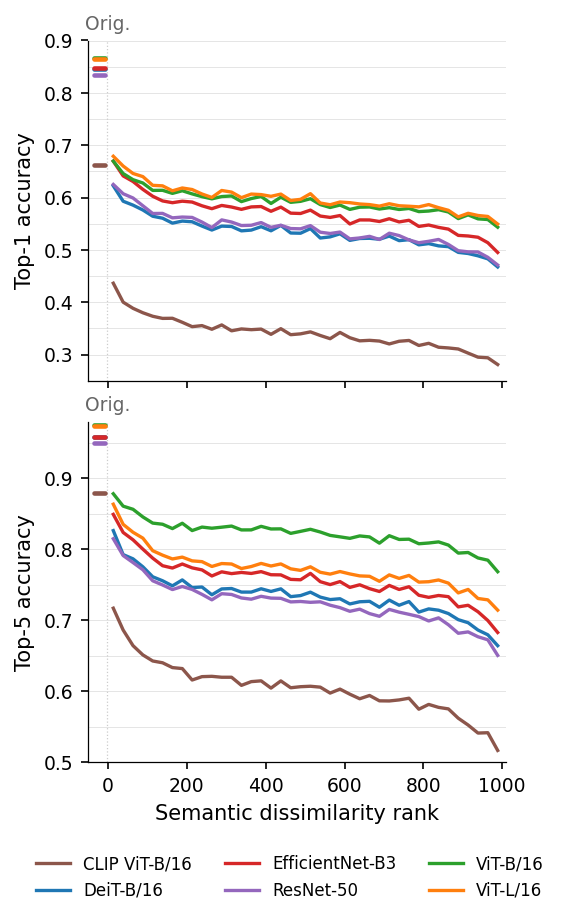

first_bin              last_bin                 drop  \
                  correct correct_top5  correct correct_top5 correct   
model                                                                  
CLIP-ViT-B-16        43.6         71.7     28.1         51.6    15.5   
DeiT-B-16            62.2         82.6     46.7         66.4    15.5   
EfficientNet-B3      67.0         84.9     49.5         68.3    17.4   
ResNet-50            62.5         81.5     47.1         65.0    15.4   
ViT-B-16             67.0         87.8     54.3         76.8    12.6   
ViT-L-16             67.9         86.4     54.9         71.4    13.0   

                              
                correct_top5  
model                         
CLIP-ViT-B-16           20.1  
DeiT-B-16               16.2  
EfficientNet-B3         16.7  
ResNet-50               16.5  
ViT-B-16                11.0  
ViT-L-16                14.9

In [4]:
composites = load_composite_predictions(PREDICTIONS_DIR, COMPOSITES_DIR / "metadata.csv", CLASS_INDEX, MAIN_MODELS)
curves = get_accuracy_curves(composites, BIN_WIDTH)
original_accuracy = get_original_accuracy(PREDICTIONS_DIR, MAIN_MODELS)

fig = plot_accuracy_vs_distance(curves, original_accuracy)
fig.savefig(FIG_DIR / "accuracy_vs_distance.pdf")
plt.show()

# Accuracy in the first and last bin and the drop between them, in percent
(100 * get_accuracy_drop(curves)).round(1)

### All models

The same for every model in `ALL_MODELS`, grouped by architecture family. Loading all 35 models takes a few minutes and around 10 GB of memory.

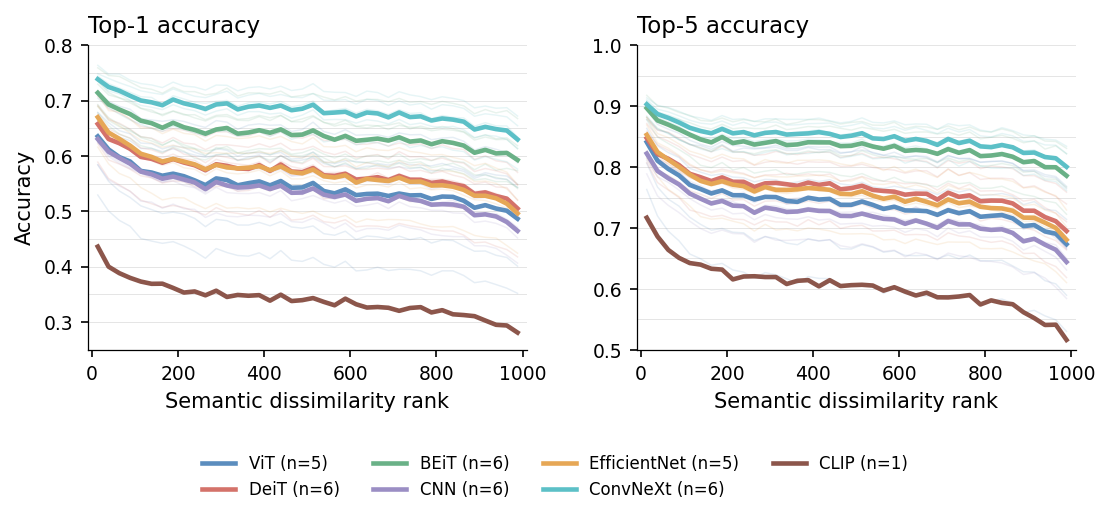

Top-1 accuracy drops by 9.2 to 19.2 percentage points from the first to the last bin


In [5]:
composites_all = load_composite_predictions(PREDICTIONS_DIR, COMPOSITES_DIR / "metadata.csv", CLASS_INDEX, ALL_MODELS)
curves_all = get_accuracy_curves(composites_all, BIN_WIDTH)

fig = plot_accuracy_vs_distance_all_models(curves_all)
fig.savefig(FIG_DIR / "accuracy_vs_distance_all_models.pdf")
plt.show()

drop = get_accuracy_drop(curves_all)["drop"]["correct"]
print(f"Top-1 accuracy drops by {100 * drop.min():.1f} to {100 * drop.max():.1f} percentage points from the first to the last bin")

## Is the decline really there for every model?

The curves above depend on how we bin the ranks. To make sure the decline is not an artefact of the binning, we fit a logistic regression for every model on the individual composites: the probability of a correct (top-1) prediction as a function of the dissimilarity rank.

A negative slope means that accuracy goes down as the object and background become less related. If the 95% confidence interval of the slope lies completely below zero, the decline is not due to chance.

In [6]:
regressions = fit_logistic_regressions(composites_all)

n_negative = (regressions["ci_high"] < 0).sum()
mean_slope = regressions["slope"].mean()
print(f"{n_negative} of {len(regressions)} models have a slope with a 95% confidence interval below zero")
print(f"Mean slope: {mean_slope:.5f} per rank (range {regressions['slope'].min():.5f} to {regressions['slope'].max():.5f})")
print(f"So every 100 ranks, the odds of a correct prediction are multiplied by {np.exp(100 * mean_slope):.3f}")

regressions.sort_values("slope")

35 of 35 models have a slope with a 95% confidence interval below zero
Mean slope: -0.00038 per rank (range -0.00048 to -0.00028)
So every 100 ranks, the odds of a correct prediction are multiplied by 0.963


,slope,ci_low,ci_high,p_value,n_images
efficientnet_b2,-0.000481,-0.000495,-0.000467,0.000000e+00,953862
vit_base_patch32_224,-0.000479,-0.000493,-0.000465,0.000000e+00,953862
vit_small_patch16_224,-0.000467,-0.000481,-0.000453,0.000000e+00,953862
resnet34,-0.000456,-0.000470,-0.000442,0.000000e+00,953862
inception_v3,-0.000456,-0.000470,-0.000442,0.000000e+00,953862
inception_v4,-0.000440,-0.000454,-0.000426,0.000000e+00,953862
efficientnetv2_rw_s,-0.000438,-0.000452,-0.000424,0.000000e+00,953862
EfficientNet-B3,-0.000438,-0.000452,-0.000424,0.000000e+00,953862
efficientnet_b4,-0.000430,-0.000445,-0.000416,0.000000e+00,953862
deit_small_patch16_224,-0.000428,-0.000442,-0.000415,0.000000e+00,953862


## Not every background behaves the same

The curves above average over all backgrounds. But does every background show the same decline? Let's look at them separately.

For each background, we group composites into bins of `TREND_BIN_WIDTH` ranks and compute accuracy in each bin, averaged over the supervised models. We then calculate the **Spearman correlation** $\rho$ between rank and accuracy. Negative values mean accuracy tends to fall with semantic distance, while positive values mean it tends to rise. Values further from zero indicate a more consistent trend.

We use fixed cutoffs to split the backgrounds into four groups:

- **Strong decline:** $\rho \leq -0.5$
- **Mild decline:** $-0.5 < \rho \leq 0$
- **Mild increase:** $0 < \rho \leq 0.5$
- **Strong increase:** $\rho > 0.5$

We then compare their accuracy curves and look at which scene categories appear in each group. Most backgrounds show a decline, with the strongest negative trends mainly coming from nature scenes. Human-related scenes appear more often in the groups with mild or positive trends.

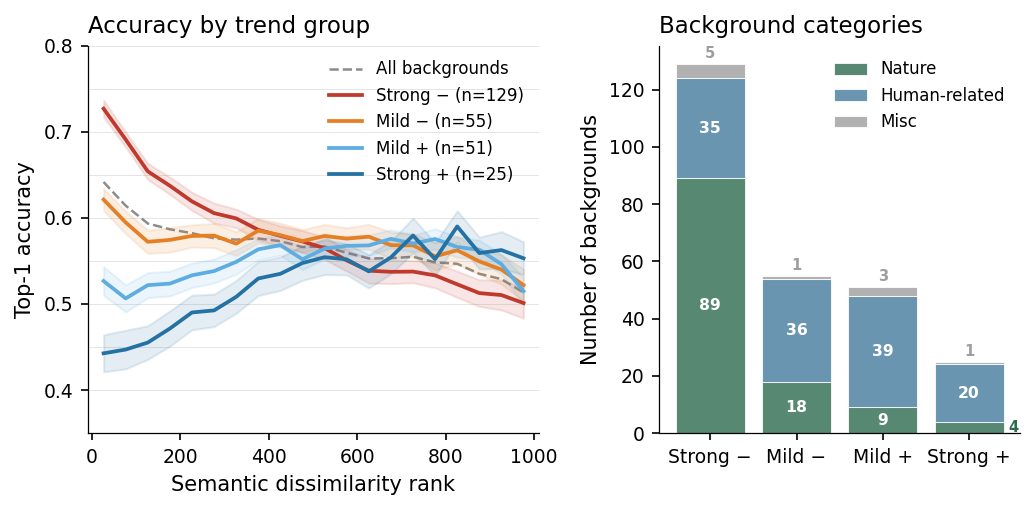

Correlation across 260 backgrounds: mean -0.32, median -0.49, std 0.52


background_category,human_related,misc,nature
group,,,
Mild +,39,3,9
Mild −,36,1,18
Strong +,20,1,4
Strong −,35,5,89


In [7]:
trends = get_background_trends(composites, SUPERVISED_MODELS, TREND_BIN_WIDTH)
group_curves = get_trend_group_curves(composites, trends, SUPERVISED_MODELS, TREND_BIN_WIDTH)

fig = plot_background_trends(group_curves, trends)
fig.savefig(FIG_DIR / "background_trends.pdf")
plt.show()

print(f"Correlation across {len(trends)} backgrounds: mean {trends['rho'].mean():.2f}, median {trends['rho'].median():.2f}, std {trends['rho'].std():.2f}")
trends.groupby(["group", "background_category"]).size().unstack(fill_value=0)

### Do human-related scenes just get different objects?

*Added for the rebuttal: a reviewer asked whether human-related backgrounds tolerate distant objects more easily simply because they receive a more diverse set of objects.*

To check this, we sort every object class into human-made, natural, food or other, using its WordNet hypernyms (the more general terms above it in the hierarchy, as in notebook 01). Animals and plants count as natural, everything under *artifact* as human-made. This is a coarse grouping, and a few classes could go either way, but it gives a good impression of what is in the object library.

Then we count, for every background, how many different object classes it is combined with.

In [8]:
import nltk
from nltk.corpus import wordnet as wn

nltk.download("wordnet", quiet=True)


def get_object_group(class_hash):
    """Sort an ImageNet class into human-made, natural, food or other, using its WordNet hypernyms."""
    synset = wn.synset_from_pos_and_offset("n", int(class_hash[1:]))
    ancestors = {hypernym.name() for path in synset.hypernym_paths() for hypernym in path}
    if "organism.n.01" in ancestors:
        return "natural"
    if "artifact.n.01" in ancestors:
        return "human-made"
    if ancestors & {"natural_object.n.01", "geological_formation.n.01"}:
        return "natural"
    if "food.n.01" in ancestors:
        return "food"
    return "other"


metadata = pd.read_csv(COMPOSITES_DIR / "metadata.csv", usecols=["background_id", "background_category", "object_image_name", "object_class_hash"])
objects = metadata.drop_duplicates("object_image_name").copy()
objects["group"] = objects["object_class_hash"].map({class_hash: get_object_group(class_hash) for class_hash in objects["object_class_hash"].unique()})

Human-made and natural objects make up roughly half of the library each. And every single background, human-related or nature, is combined with exactly the same set of object classes. So human-related scenes do not get a more diverse object pool than nature scenes.

In [9]:
classes_per_background = metadata.groupby("background_id")["object_class_hash"].nunique()
print(f"Object classes per background: {classes_per_background.min()} to {classes_per_background.max()}")

composition = pd.DataFrame({
    "classes": objects.drop_duplicates("object_class_hash")["group"].value_counts(),
    "objects": objects["group"].value_counts(),
})
composition["share of objects (%)"] = (100 * composition["objects"] / composition["objects"].sum()).round(1)
composition

Object classes per background: 918 to 918


,classes,objects,share of objects (%)
group,,,
human-made,454,6075,49.3
natural,426,5719,46.4
food,22,293,2.4
other,16,233,1.9


## Does this depend on the semantic axis?

So far, we have measured semantic distance using the consensus axis from notebook 01. But would we see the same decline with other ways of measuring how related two classes are?

We keep the composites and predictions the same, but plot accuracy using three alternative measures:

- **Individual classifier heads:** the dissimilarity matrices from single models, before combining them into the consensus.
- **CLIP text:** dissimilarities between text embeddings of `"a photo of a {class}"`.
- **WordNet:** the number of hops between the object and background classes in the WordNet hierarchy.

The individual classifier heads still show the decline, although it is a bit weaker than with the consensus. CLIP text and WordNet give very different curves. So the pattern seems tied to how visual classifiers organise the classes. It does not appear with every measure of semantic similarity.

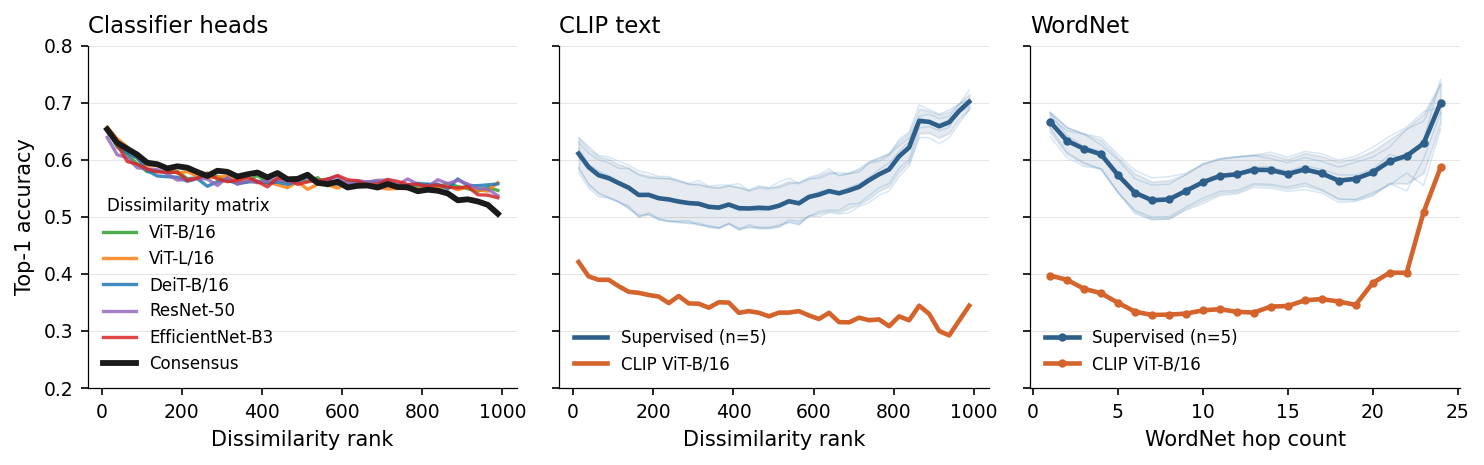

ViT-B-16         top-1 accuracy drops by 10.8 percentage points
ViT-L-16         top-1 accuracy drops by 9.7 percentage points
DeiT-B-16        top-1 accuracy drops by 9.3 percentage points
ResNet-50        top-1 accuracy drops by 10.2 percentage points
EfficientNet-B3  top-1 accuracy drops by 11.8 percentage points
Consensus        top-1 accuracy drops by 14.8 percentage points


In [10]:
hash_to_idx = load_class_hash_index(CLASS_INDEX)
supervised = composites[composites["model"].isin(SUPERVISED_MODELS)]

# Mean accuracy of the supervised models when ranking by each single classifier head, and by the consensus.
head_curves = {}
for model, head in HEAD_MATRICES.items():
    matrix = np.load(SEMANTIC_AXES_DIR / "individual_heads" / f"{head}.npy")
    head_curves[model] = get_model_curves(rerank_composites(supervised, matrix, hash_to_idx), BIN_WIDTH).mean(axis=1)
head_curves["Consensus"] = get_model_curves(supervised, BIN_WIDTH).mean(axis=1)

# Accuracy of every main model when ranking by CLIP text embeddings and by WordNet hops.
clip_curves = get_model_curves(rerank_composites(composites, np.load(SEMANTIC_AXES_DIR / "clip_text.npy"), hash_to_idx), BIN_WIDTH)
wordnet_curves = get_wordnet_curves(composites, np.load(SEMANTIC_AXES_DIR / "wordnet.npy"), hash_to_idx)

fig = plot_alternative_axes(head_curves, clip_curves, wordnet_curves, SUPERVISED_MODELS)
fig.savefig(FIG_DIR / "alternative_axes.pdf")
plt.show()

for name, curve in head_curves.items():
    print(f"{name:16s} top-1 accuracy drops by {100 * (curve.iloc[0] - curve.iloc[-1]):.1f} percentage points")